# Experiment: STDAN-style (spatial-temporal dynamic attention)

Re-implementation of the idea of STDAN (Chen et al., IEEE T-ITS 2022), STRAP's strongest baseline: per-vehicle LSTM encoding, the target attends over its neighbours at every history step (dynamic spatial attention), temporal attention over the resulting sequence, gated fusion, and an intention head over lateral x longitudinal manoeuvres that conditions the decoder. No public code was found, so this follows the paper's description, not its exact layers. Paper NGSIM RMSE (STRAP Table I): 0.43 / 1.01 / 1.69 / 2.56 / 3.65 m.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | Written from the paper's description; layer sizes are ours (d=64, 4 heads, decoder LSTM 128). | No public STDAN code was found (MODEL_ALTERNATIVES.md). | Exact STDAN layer counts and sizes are unverified. |
| M2 | Per-vehicle encoder: FC(11->64) + ELU + LSTM(64) over all 11 features. | Same inputs as every model (S5). | - |
| M3 | Spatial attention: at each of the 30 steps the target's hidden state queries all real vehicles (key padding mask). | STDAN's 'dynamic' attention = weights recomputed per timestep. | STRAP's spatial encoder is all-to-all; STDAN is target-centred. |
| M4 | Temporal attention over the 30 interaction-aware steps, then a GLU gate fuses it with the target's own history; last step = context. | STDAN fuses spatial-temporal features with gating. | - |
| M5 | 6 LATENT intentions (3 lateral x 2 longitudinal): a softmax head weights 6 mode-conditioned decoder runs, moment-matched to one Gaussian. | No manoeuvre labels reach the model (`fit` passes only states), so intentions are learned only through the trajectory loss. | STDAN supervises the intention head with manoeuvre labels; ours may not learn interpretable manoeuvres. |
| M6 | Moment matching as in STRAP's decoder. | Our output contract is one Gaussian (S7). | Paper scores the most likely manoeuvre's trajectory. |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "stdan"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "STDAN-style: per-step spatial attention + temporal attention + 6 latent intentions"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-30 03:27:22,103 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-30 03:27:29,488 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-30 03:27:30,294 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-30 03:27:30,320 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-30 03:27:30,348 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-30 03:45:22,271 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-30 03:45:52,000 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/stdan/intention_clusters.pkl


2026-10-30 03:45:53,549 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** paper-description re-implementation (M1); 11-feature encoder (M2); target-centred per-step spatial attention (M3); temporal attention + GLU fusion (M4); 6 latent intentions, moment-matched (M5, M6).

In [4]:
def moment_match(raw, weights):
    """(B, M, T, 5) raw mode outputs + (B, M) mode weights -> (B, T, 5) one Gaussian (M6)."""
    mu = raw[..., :2]
    sig = F.softplus(raw[..., 2:4]) + 1e-3
    rho = torch.tanh(raw[..., 4])
    w = weights[:, :, None]                                         # (B, M, 1)
    mean = (w[..., None] * mu).sum(1)                               # (B, T, 2)
    d = mu - mean[:, None]
    var = (w[..., None] * (sig ** 2 + d ** 2)).sum(1)
    cov = (w * (rho * sig[..., 0] * sig[..., 1] + d[..., 0] * d[..., 1])).sum(1)
    sx, sy = var[..., 0].sqrt(), var[..., 1].sqrt()
    return torch.stack([mean[..., 0], mean[..., 1], sx, sy, (cov / (sx * sy)).clamp(-0.999, 0.999)], dim=-1)


class STDAN(nn.Module):
    """Spatial-temporal dynamic attention with latent manoeuvre intentions (STDAN-style)."""
    def __init__(self, input_dim=STATE_DIM, d=64, heads=4, dec=128, T_f=TF_STEPS, n_lat=3, n_lon=2):
        super().__init__()
        self.T_f, self.M = T_f, n_lat * n_lon
        self.embed = nn.Linear(input_dim, d)
        self.encoder = nn.LSTM(d, d, batch_first=True)
        self.spatial = nn.MultiheadAttention(d, heads, batch_first=True)
        self.temporal = nn.MultiheadAttention(d, heads, batch_first=True)
        self.gate = nn.Linear(2 * d, 2 * d)                         # GLU fusion
        self.norm = nn.LayerNorm(d)
        self.intention = nn.Linear(d, self.M)                       # M5: latent intention logits
        self.mode_embed = nn.Embedding(self.M, d)
        self.decoder = nn.LSTM(2 * d, dec, batch_first=True)
        self.out = nn.Linear(dec, 5)

    def forward(self, states, mask, dims=None):
        B, T_h, N, D_in = states.shape
        x = F.elu(self.embed(states)).transpose(1, 2).reshape(B * N, T_h, -1)
        h, _ = self.encoder(x)
        h = h.reshape(B, N, T_h, -1)                                # per vehicle, per step
        # M3: at every step the target queries all real vehicles (itself included, so never all-masked).
        query = h[:, 0].reshape(B * T_h, 1, -1)
        keys = h.transpose(1, 2).reshape(B * T_h, N, -1)
        pad = (~mask)[:, None].expand(B, T_h, N).reshape(B * T_h, N)
        s, _ = self.spatial(query, keys, keys, key_padding_mask=pad)
        s = s.reshape(B, T_h, -1)
        t, _ = self.temporal(s, s, s)                               # M4: attention over the 30 steps
        fused = F.glu(self.gate(torch.cat([h[:, 0], t], dim=-1)), dim=-1)
        context = self.norm(fused + h[:, 0])[:, -1]                 # (B, d) last step
        weights = torch.softmax(self.intention(context), dim=-1)    # (B, M)
        dec_in = torch.cat([context[:, None].expand(-1, self.M, -1),
                            self.mode_embed.weight[None].expand(B, -1, -1)], dim=-1)
        out, _ = self.decoder(dec_in.reshape(B * self.M, 1, -1).expand(-1, self.T_f, -1))
        raw = self.out(out).reshape(B, self.M, self.T_f, 5)
        return moment_match(raw, weights), states.new_zeros(B, N - 1, 4), None


def build_model():
    return STDAN()

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

STDAN: 217,483 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-30 03:45:54,390 - STRAP - INFO - Training STRAP on cuda


2026-10-30 03:45:54,391 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-30 03:45:54,391 - STRAP - INFO - Number of training batches: 4220


2026-10-30 03:45:54,393 - STRAP - INFO - Number of validation batches: 673


2026-10-30 03:47:24,216 - STRAP - INFO - Epoch 1/12: Train Loss=644.2817 (goal=598.7866, traj=45.4952), Val Loss=392.0501, Val RMSE=2.2319


...

2026-10-30 04:01:27,352 - STRAP - INFO - Epoch 11/12: Train Loss=604.8492 (goal=598.7885, traj=6.0607), Val Loss=391.1085, Val RMSE=2.0734


2026-10-30 04:01:27,356 - STRAP - INFO -   -> Saved best checkpoint (val_loss=391.1085)


2026-10-30 04:02:51,337 - STRAP - INFO - Epoch 12/12: Train Loss=604.8435 (goal=598.7876, traj=6.0559), Val Loss=391.1113, Val RMSE=2.0741


2026-10-30 04:02:51,356 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,644.281729,598.786562,45.495168,392.050148,2.231884,0.000300
1,2,606.027933,598.787949,7.239984,391.679905,2.153668,0.000180
2,3,605.474801,598.787596,6.687205,391.415170,2.109162,0.000108
3,4,605.214723,598.786922,6.427800,391.748641,2.178948,0.000065
4,5,605.070694,598.786874,6.283820,391.192363,2.076765,0.000039
5,6,604.975943,598.785039,6.190904,391.209062,2.084743,0.000023
6,7,604.923517,598.784431,6.139087,391.170753,2.076052,0.000014
7,8,604.890902,598.787485,6.103417,391.141718,2.077596,0.000008
8,9,604.868518,598.785813,6.082705,391.149315,2.080775,0.000005
9,10,604.859336,598.790734,6.068603,391.126345,2.076811,0.000003


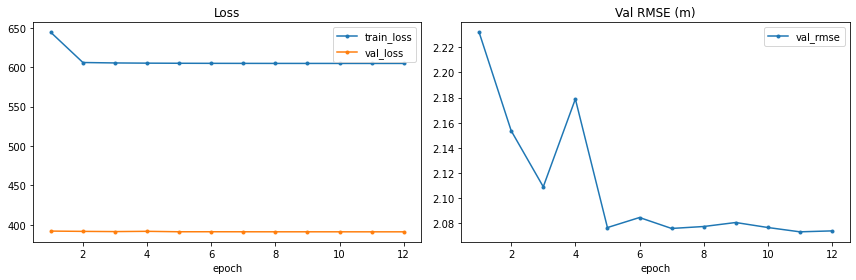

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.454745,1.121762,1.927273,2.927767,4.136496,2.113608,121130.0
site us-101,0.425012,1.079170,1.889947,2.921433,4.187203,2.100553,62135.0
zero-neighbour samples,0.536246,1.301071,2.263105,3.485678,4.969673,2.511155,3120.0
site i-80,0.484088,1.164938,1.965819,2.934420,4.082406,2.126334,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/stdan.json


PosixPath('/home/st_students/MTP/experiments/results/stdan.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
miat,MIAT: temporal transformer + spatial attention + weighted manoeuvre-intention supervision,"us-101,i-80",12,194986,0.4489,1.1007,1.8873,2.8658,4.0551,2.0716,2.0952,2.4868,2.0456
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
stdan,STDAN-style: per-step spatial attention + temporal attention + 6 latent intentions,"us-101,i-80",12,217483,0.4547,1.1218,1.9273,2.9278,4.1365,2.1136,2.1006,2.5112,2.1263
mfp,"MFP: GRU encoders + attention, 5 latent modes, autoregressive GRU decoders","us-101,i-80",12,77786,0.4536,1.1207,1.9280,2.9284,4.1388,2.1139,2.1002,2.5112,2.1274
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
inatran,LOOSE: interaction-aware spatio-temporal transformer with future-step queries,"us-101,i-80",12,173381,0.4740,1.1277,1.9305,2.9271,4.1289,2.1176,2.1055,2.5476,2.1297
physics_informed,"Physics-informed: wavelet history reconstruction, wave fusion, risk-aware pooling, per-mode kinematic decoding","us-101,i-80",12,212684,0.4781,1.1383,1.9378,2.9287,4.1371,2.1240,2.1018,2.4867,2.1463
mha_lstm,MHA-LSTM: each attention head over neighbours yields one trajectory mode,"us-101,i-80",12,146825,0.4637,1.1367,1.9448,2.9449,4.1597,2.1300,2.1281,2.5236,2.1308
gava,LOOSE (name only): gated attention + conditional VAE,"us-101,i-80",12,210757,0.4679,1.1431,1.9574,2.9665,4.1877,2.1445,2.1282,2.5460,2.1605


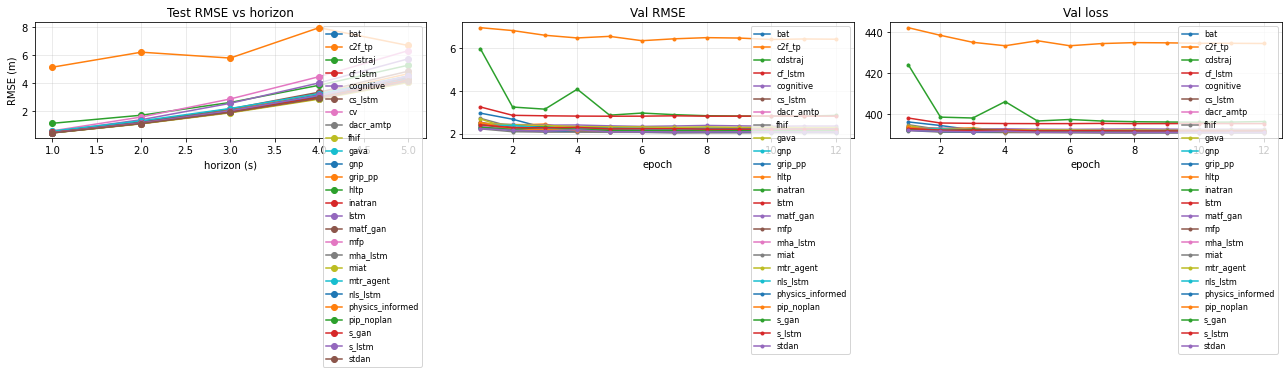

In [9]:
rmse_df, collision_df = compare()